# Example of the aitlas toolbox in the context of image segmentation

This notebook shows a sample implementation of a image segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import mPv4gerSegDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/m_pv4ger_seg/data/",
    "csv_file": "./data/m_pv4ger_seg/1.00x_train_partition.json",
    "mode": "train"
}
dataset = mPv4gerSegDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 3221


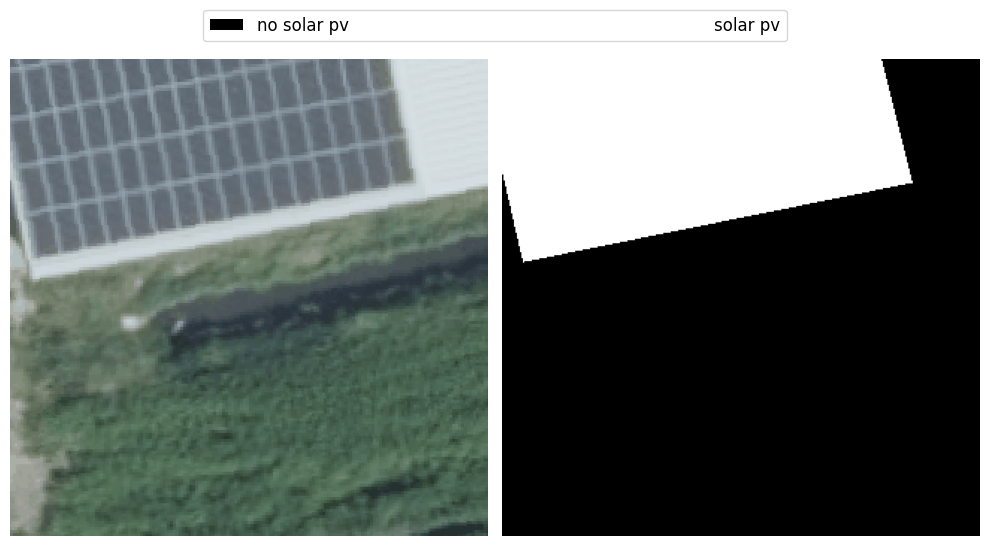

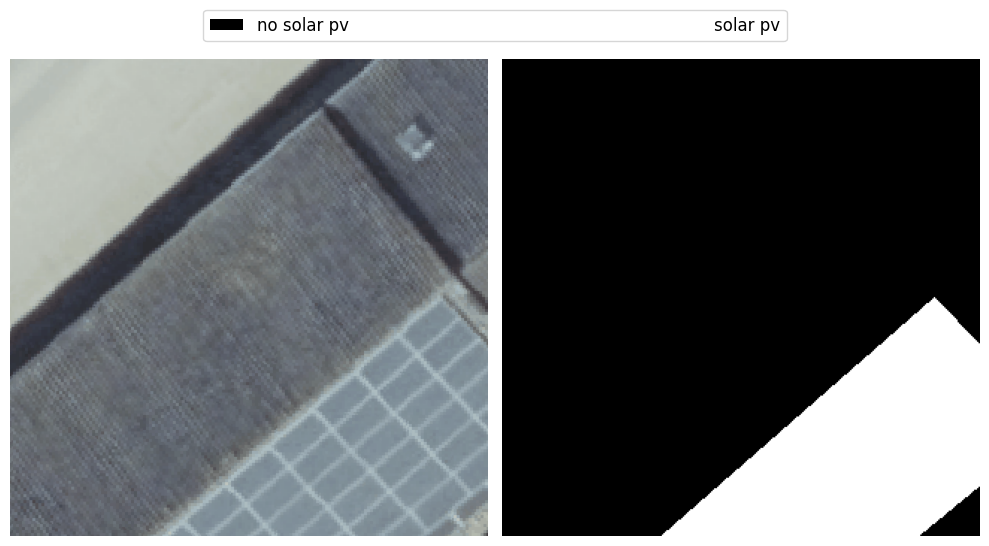

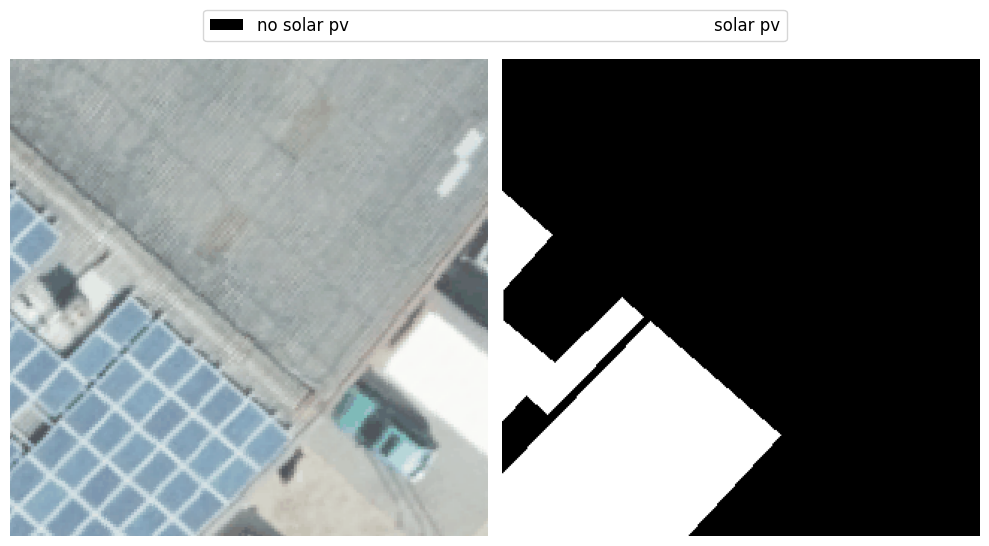

In [25]:
dataset.show_image(10)
dataset.show_image(100)
dataset.show_image(300);

In [26]:
dataset.data_distribution_table()

,Number of pixels
no solar pv,266476616.0
solar pv,63353784.0


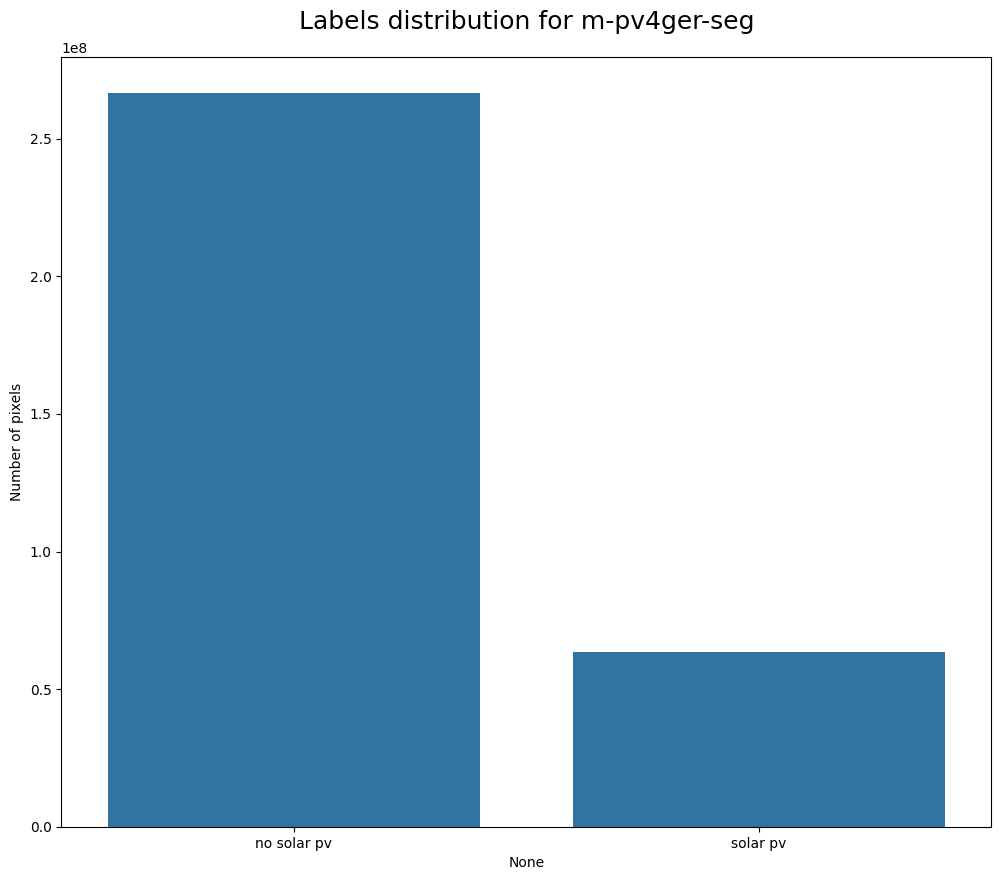

In [27]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/m_pv4ger_seg/data/",
    "csv_file": "./data/m_pv4ger_seg/1.00x_train_partition.json",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = mPv4gerSegDataset(train_dataset_config)

len(train_dataset)

3221

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/m_pv4ger_seg"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [33]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2026-04-28 11:41:37,064 INFO Starting training.
training: 100%|██████████| 403/403 [00:35<00:00, 11.30it/s]
2026-04-28 11:42:12,816 INFO epoch: 1, time: 35, loss:  0.17162
testing on train set: 100%|██████████| 403/403 [00:13<00:00, 30.96it/s]
2026-04-28 11:42:27,494 INFO IOU:0.9497591054213997, IOU mean:0.9170428975489896, IOU per Class:[0.97233975 0.86174604]
training: 100%|██████████| 403/403 [00:36<00:00, 11.15it/s]
2026-04-28 11:43:03,639 INFO epoch: 2, time: 36, loss:  0.05994
testing on train set: 100%|██████████| 403/403 [00:13<00:00, 30.35it/s]
2026-04-28 11:43:16,932 INFO IOU:0.9591165874635913, IOU mean:0.9352634025014901, IOU per Class:[0.97458366 0.89594314]
training: 100%|██████████| 403/403 [00:35<00:00, 11.30it/s]
2026-04-28 11:43:52,609 INFO epoch: 3, time: 36, loss:  0.03590
testing on train set: 100%|██████████| 403/403 [00:13<00:00, 30.38it/s]
2026-04-28 11:44:05,887 INFO IOU:0.9628506535424023, IOU mean:0.9412959674950836, IOU per Class:[0.97661208 0.90597986]
trai

0.017020275488435686

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir" : "./data/m_pv4ger_seg/data/",
    "csv_file": "./data/m_pv4ger_seg/1.00x_train_partition.json",
    "mode": "valid",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = mPv4gerSegDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/m_pv4ger_seg/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

403


2026-04-28 11:49:55,731 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger_seg/checkpoint.pth.tar
2026-04-28 11:49:56,088 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger_seg/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 101/101 [00:02<00:00, 45.13it/s]


[{'IOU': 0.9598612943869353,
  'IOU mean': 0.9360624374431373,
  'IOU per Class': array([0.97643818, 0.89568669])}]

## Predictions

2026-04-28 11:50:01,331 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger_seg/checkpoint.pth.tar
2026-04-28 11:50:01,660 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/m_pv4ger_seg/checkpoint.pth.tar at epoch 11


403


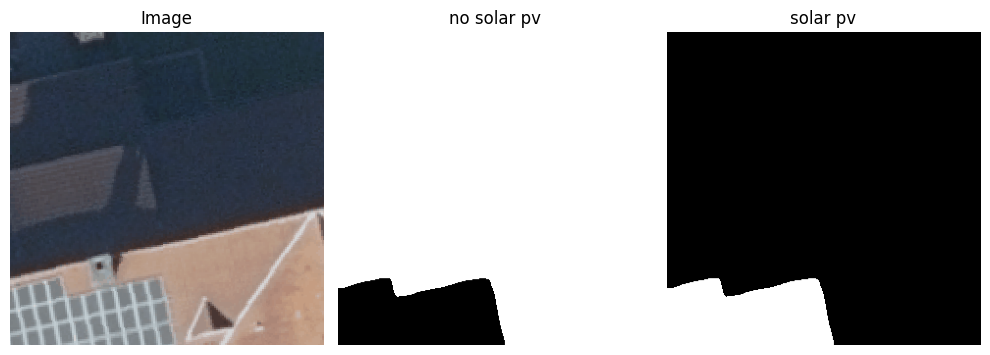

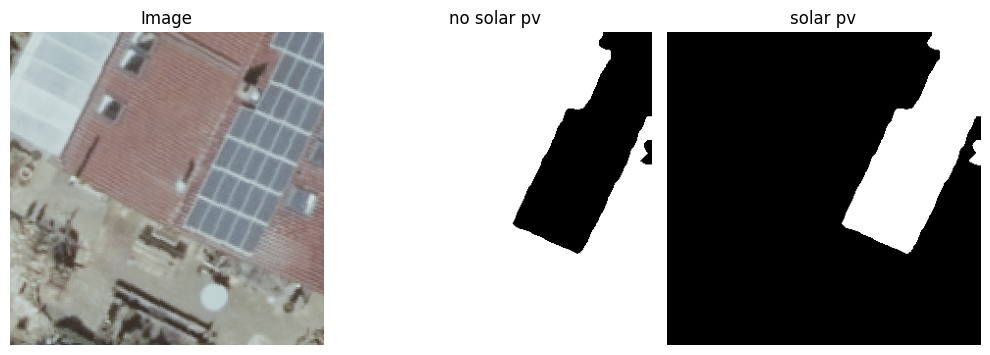

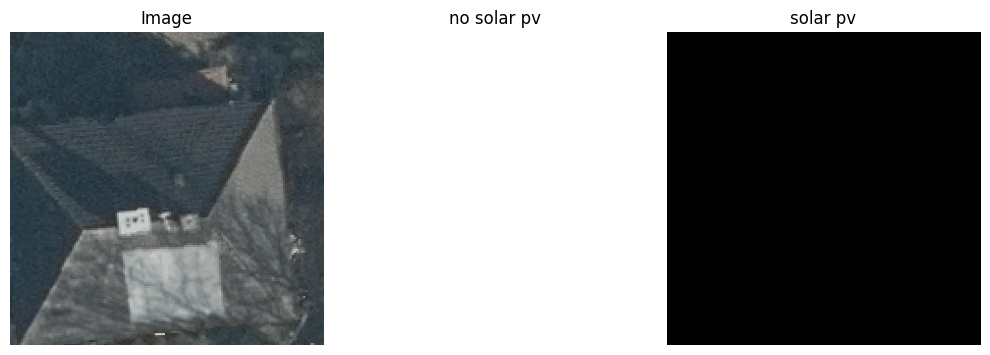

In [ ]:
model_path = "./data/experiments/m_pv4ger_seg/checkpoint.pth.tar"
labels = ["no solar pv","solar pv"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/m_pv4ger_seg/data/",
    "csv_file": "./data/m_pv4ger_seg/1.00x_train_partition.json",
    "mode": "test"
}

test_dataset = mPv4gerSegDataset(test_dataset_config)
print(len(test_dataset))

image = test_dataset[0][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[10][0]
fig = model.predict_masks(image, labels, transform)

image = test_dataset[50][0]
fig = model.predict_masks(image, labels, transform)